# **Notebook 5: Solution V1 — RAG Evaluation**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./chroma_db/` — Created by Notebook 4
- [ ] `df_test.csv` — Created by Notebook 2
- [ ] `outputs.json` — Created by Notebooks 3+4
- [ ] GPU runtime enabled

**Files this notebook will CREATE:**
- [ ] `v1_metrics.csv` — Per-row Baseline vs V1 scores _(Evidence for comparative analysis)_

---

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Setup
Installs dependencies, defines helpers and (for Notebooks 3-7) loads the shared `config.json` written by Notebook 2. Run this cell first.

In [3]:
# ---- Environment setup (Google Colab / local Jupyter) ----
import os, sys, glob, zipfile, json, random, warnings
warnings.filterwarnings("ignore")

USE_DRIVE = False   # set True on Colab to keep artifacts (chroma_db, adapters, csv) across runtime resets
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORKDIR = "/content/drive/MyDrive/RAG/Dataset/Output"
    os.makedirs(WORKDIR, exist_ok=True)
    os.chdir(WORKDIR)
print("Working directory:", os.getcwd())

%pip install -q transformers accelerate bitsandbytes sentence-transformers chromadb langchain langchain-community langchain-huggingface langchain-chroma rouge-score nltk scikit-learn matplotlib seaborn

def find_sop_dir():
    """Locate the folder holding the Markdown SOP files (corporate_policies/ or Dataset/sop_documents/).
    If it is not present, try to unzip a Dataset*.zip, and finally ask for an upload on Colab."""
    def _search():
        for c in ["corporate_policies", os.path.join("Dataset", "sop_documents"), "sop_documents"]:
            if os.path.isdir(c) and glob.glob(os.path.join(c, "*.md")):
                return c
        for pat in ["**/sop_documents", "**/corporate_policies"]:
            for h in glob.glob(pat, recursive=True):
                if glob.glob(os.path.join(h, "*.md")):
                    return h
        return None
    found = _search()
    if found: return found
    for z in glob.glob("*.zip") + glob.glob("**/Dataset*.zip", recursive=True):
        with zipfile.ZipFile(z) as zf: zf.extractall(".")
        found = _search()
        if found: return found
    try:
        from google.colab import files
        print("SOP folder not found - please upload Dataset.zip (contains sop_documents/*.md)")
        for name in files.upload():
            if name.endswith(".zip"):
                with zipfile.ZipFile(name) as zf: zf.extractall(".")
        found = _search()
        if found: return found
    except ImportError:
        pass
    raise FileNotFoundError("Could not find the SOP .md files. Place them in ./corporate_policies/ or ./Dataset/sop_documents/")

# ---- Load the single-source-of-truth configuration written by Notebook 2 ----
if not os.path.exists("/content/drive/MyDrive/RAG/Dataset/Output/config.json"):
    raise FileNotFoundError("config.json not found - run Notebook 2 (Data Preparation) first.")
cfg = json.load(open("/content/drive/MyDrive/RAG/Dataset/Output/config.json"))
MODEL_ID       = cfg["MODEL_ID"]
EMBED_MODEL    = cfg["EMBED_MODEL"]
SEED           = cfg["SEED"]
BASELINE_SYSTEM = cfg["BASELINE_SYSTEM"]
RAG_SYSTEM     = cfg["RAG_SYSTEM"]          # contains the {context} placeholder
ROUTER_SYSTEM  = cfg["ROUTER_SYSTEM"]
MAX_NEW_TOKENS = cfg["MAX_NEW_TOKENS"]
CHROMA_DIR     = cfg["CHROMA_DIR"]
COLLECTION     = cfg["COLLECTION"]
random.seed(SEED)
print("MODEL_ID:", MODEL_ID, "| EMBED_MODEL:", EMBED_MODEL, "| SEED:", SEED)

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

HAS_CUDA = torch.cuda.is_available()
COMPUTE_DTYPE = torch.bfloat16 if (HAS_CUDA and torch.cuda.get_device_capability()[0] >= 8) else torch.float16
print("CUDA available:", HAS_CUDA, "| compute dtype:", COMPUTE_DTYPE)
if not HAS_CUDA:
    print("WARNING: no GPU found. Runtime -> Change runtime type -> T4 GPU. Falling back to (slow) CPU float32.")

def load_base_model(model_id=None, quantize=True):
    """Load tokenizer + base model. 4-bit NF4 quantisation on GPU (about 1 GB VRAM for the 1.5B model)."""
    model_id = model_id or MODEL_ID
    tok = AutoTokenizer.from_pretrained(model_id)
    tok.padding_side = "left"                       # required for batched decoder-only generation
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    if HAS_CUDA and quantize:
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                 bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=COMPUTE_DTYPE)
        model = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=bnb, device_map={"": 0})
    elif HAS_CUDA:
        model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=COMPUTE_DTYPE, device_map={"": 0})
    else:
        model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=torch.float32)
    model.eval()
    return tok, model

@torch.no_grad()
def generate_chat(model, tok, messages_list, max_new_tokens=None, batch_size=16):
    """Deterministic (greedy) batched generation. do_sample=False with temperature/top_p/top_k=None
    (never temperature=0.0 together with do_sample=False). Returns only the newly generated text."""
    max_new_tokens = max_new_tokens or MAX_NEW_TOKENS
    outs = []
    for i in range(0, len(messages_list), batch_size):
        batch = messages_list[i:i + batch_size]
        prompts = [tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in batch]
        enc = tok(prompts, return_tensors="pt", padding=True).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None, pad_token_id=tok.pad_token_id)
        new_tokens = gen[:, enc["input_ids"].shape[1]:]
        outs += [t.strip() for t in tok.batch_decode(new_tokens, skip_special_tokens=True)]
    return outs

def baseline_messages(query):
    return [{"role": "system", "content": BASELINE_SYSTEM}, {"role": "user", "content": query}]

def rag_messages(query, context):
    return [{"role": "system", "content": RAG_SYSTEM.format(context=context)}, {"role": "user", "content": query}]

try:
    from langchain_huggingface import HuggingFaceEmbeddings
except ImportError:
    from langchain_community.embeddings import HuggingFaceEmbeddings
try:
    from langchain_chroma import Chroma
except ImportError:
    from langchain_community.vectorstores import Chroma

def get_embeddings():
    # SAME model + settings in every notebook (NB4, NB5, NB7). CPU is enough for MiniLM.
    return HuggingFaceEmbeddings(model_name=EMBED_MODEL, model_kwargs={"device": "cpu"},
                                 encode_kwargs={"normalize_embeddings": True})

def load_vector_db(embeddings):
    return Chroma(persist_directory=CHROMA_DIR, embedding_function=embeddings, collection_name=COLLECTION)

Working directory: /content
MODEL_ID: Qwen/Qwen2.5-1.5B-Instruct | EMBED_MODEL: sentence-transformers/all-MiniLM-L6-v2 | SEED: 42
CUDA available: True | compute dtype: torch.float16


### **Task 3.3: Evaluate Solution V1**

> This task is split into five measurements (3.3.1–3.3.5). Run the shared setup cell below first (it loads the model, ChromaDB, and test data), then work through each measurement.

**── Shared setup ──**
Load the base model, reload ChromaDB (same embedding model as NB4), and load `df_test.csv` + `outputs.json`. Define helper functions `generate_baseline()` and `generate_naive_rag()` here so every subtask below can reuse them.

In [6]:
import time
import matplotlib.pyplot as plt, seaborn as sns

import re, difflib
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rouge_score import rouge_scorer
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

SOP_DIR = find_sop_dir()
SOP_RAW = {os.path.basename(f): open(f, encoding="utf-8").read() for f in sorted(glob.glob(os.path.join(SOP_DIR, "*.md")))}
INTENT_TO_SOP = cfg["INTENT_TO_SOP"]
INTENT_SEARCH = cfg["INTENT_SEARCH"]

def sop_sentences(md_text):
    """Split a Markdown SOP into clean sentences (headings dropped, wrapped lines re-joined)."""
    items, cur = [], []
    for line in md_text.splitlines():
        s = line.strip()
        if not s or s.startswith("#"):
            if cur: items.append(" ".join(cur)); cur = []
            continue
        if re.match(r"^([-*]|\d+[.)])\s+", s):
            if cur: items.append(" ".join(cur))
            cur = [re.sub(r"^([-*]|\d+[.)])\s+", "", s)]
        else:
            cur.append(s)
    if cur: items.append(" ".join(cur))
    sents = []
    for it in items:
        it = re.sub(r"[*_`]", "", it)
        sents += [x.strip() for x in re.split(r"(?<=[.!?])\s+", it) if len(x.split()) >= 4]
    return sents

SOP_SENTS = {k: sop_sentences(v) for k, v in SOP_RAW.items()}

def build_reference(query, sop_file, top_n=4):
    """SOP-grounded reference: the top-N SOP sentences of the CORRECT SOP (known from the true intent)
    that are most similar to the customer query. Identical for every system -> fair comparison."""
    sents = SOP_SENTS[sop_file]
    try:
        vec = TfidfVectorizer(stop_words="english").fit(sents + [query])
        sims = cosine_similarity(vec.transform([query]), vec.transform(sents))[0]
        keep = sorted(np.argsort(-sims)[:top_n])
    except ValueError:
        keep = list(range(min(top_n, len(sents))))
    return " ".join(sents[i] for i in keep)

_rouge = rouge_scorer.RougeScorer(["rouge1", "rougeL"], use_stemmer=True)
_smooth = SmoothingFunction().method1
def words(t): return re.findall(r"[a-z0-9']+", t.lower())

def score_output(output, reference):
    r = _rouge.score(reference, output)
    o, ref = words(output), words(reference)
    bleu = sentence_bleu([ref], o, smoothing_function=_smooth) if o else 0.0
    return r["rouge1"].fmeasure, r["rougeL"].fmeasure, bleu

def format_ok(text):
    """Free-text 'format adherence': non-empty, decodable, at least 5 words."""
    return bool(text) and "\ufffd" not in text and len(text.split()) >= 5

NUM_RE = re.compile(r"\d+(?:\.\d+)?")
ENTITY_RE = re.compile(r"\b(?:[A-Z][A-Za-z]+\s){1,3}(?:Department|Team|Portal|System|Hotline|Center|Centre|Desk|Division|Tracker)\b")
CONTACT_RE = re.compile(r"(https?://\S+|www\.\S+|[\w.+-]+@[\w-]+\.[\w.]+|\b\d{3}[-.\s]\d{3}[-.\s]\d{4}\b|\b1-800[-\d]*)")
OVERPROMISE_RE = re.compile(r"\b(guarantee[ds]?|definitely|promise[ds]?|within the hour)\b", re.I)

def _strip_list_numbers(t):
    return re.sub(r"(?m)^\s*\d+[.)]\s+", "", t)

def detect_hallucination(output, query, sop_file):
    """Rule-based, reproducible proxy for hallucination. An output is flagged if it contains
       (a) numbers/time-frames that appear neither in the CORRECT SOP nor in the customer query,
       (b) invented departments/systems/portals not named in the SOP,
       (c) contact details (URL / e-mail / phone) not in the SOP,
       (d) over-promising language (guarantee / definitely / promise) - the SOPs tell agents NOT to promise dates."""
    sop = SOP_RAW[sop_file]; sop_l = sop.lower()
    out = _strip_list_numbers(output)
    sop_nums, q_nums = set(NUM_RE.findall(sop)), set(NUM_RE.findall(query))
    bad_nums = sorted({n for n in NUM_RE.findall(out) if n not in sop_nums and n not in q_nums})
    ents = sorted({e for e in ENTITY_RE.findall(out) if e.lower() not in sop_l})
    contacts = sorted({c for c in CONTACT_RE.findall(out) if str(c).lower() not in sop_l})
    over = sorted({m.lower() for m in OVERPROMISE_RE.findall(out)})
    flagged = bool(bad_nums or ents or contacts or over)
    return {"flag": int(flagged), "unsupported_numbers": bad_nums, "invented_entities": ents,
            "invented_contacts": contacts, "over_promises": over}

def pct_change(new, old):
    return float("nan") if (old is None or old == 0 or pd.isna(old) or pd.isna(new)) else (new - old) / old * 100.0

# ---- model, vector DB, data (same MODEL_ID / embedding model / retrieval config as NB3 + NB4) -------------------
tokenizer, base_model = load_base_model(MODEL_ID, quantize=True)
embeddings = get_embeddings()
vector_db = load_vector_db(embeddings)
RETRIEVAL_K = cfg["RETRIEVAL_K"]

# Automatically populate Chroma database if it is found to be empty
if vector_db._collection.count() == 0:
    print("Chroma database is empty. Populating with documents from SOP_RAW...")
    docs, metadatas = [], []
    for name, content in SOP_RAW.items():
        docs.append(content)
        metadatas.append({"source": name, "doc_name": name})
    vector_db.add_texts(texts=docs, metadatas=metadatas)

print("Chroma documents:", vector_db._collection.count())
assert vector_db._collection.count() == len(SOP_RAW)

df_test = pd.read_csv("/content/drive/MyDrive/RAG/Dataset/Output/df_test.csv")
outputs = json.load(open("/content/drive/MyDrive/RAG/Dataset/Output/outputs.json"))
print("df_test:", df_test.shape, "| outputs.json keys:", list(outputs))

EVAL_N = None            # None = FULL held-out test set. Set e.g. 50 only if compute-constrained (df_test.sample(50)).
df_eval = df_test.copy() if EVAL_N is None else df_test.sample(EVAL_N, random_state=SEED).reset_index(drop=True)
df_eval["true_sop"] = df_eval["intent"].map(INTENT_TO_SOP)
print("Rows evaluated:", len(df_eval))

def retrieve_naive(query):
    """Naive RAG retrieval: raw customer query -> top-k SOP (k=1)."""
    d = vector_db.similarity_search(query, k=RETRIEVAL_K)[0]
    return os.path.basename(d.metadata["source"]) if "source" in d.metadata else d.metadata["doc_name"], d.page_content

def generate_baseline(queries):
    """Baseline: no context."""
    return generate_chat(base_model, tokenizer, [baseline_messages(q) for q in queries], batch_size=16)

def generate_naive_rag(queries):
    """Naive RAG: raw query -> retrieve top-1 SOP -> SOP injected into the system prompt."""
    rets = [retrieve_naive(q) for q in queries]
    outs = generate_chat(base_model, tokenizer, [rag_messages(q, ctx) for q, (_, ctx) in zip(queries, rets)], batch_size=16)
    return [{"output": o, "source": s} for o, (s, _) in zip(outs, rets)]

# quick smoke test on the Notebook-3 query
print("Smoke test (baseline):", generate_baseline([outputs["test_query"]])[0][:120], "...")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Chroma documents: 13
df_test: (400, 4) | outputs.json keys: ['test_query', 'ground_truth', 'baseline_output', 'baseline_assessment', 'model_id', 'naive_rag_output', 'naive_rag_retrieved_source', 'naive_rag_retrieval_correct']
Rows evaluated: 400
Smoke test (baseline): It's important to check your shipping confirmation for any updates or delays, as they can vary depending on the carrier  ...


#### **3.3.1 Execute Automated Testing [3 marks]**
**The Task:** Run both Baseline and Naive RAG across the entire held-out test set, collecting their generated outputs for every row.

**Hints & Tips:**
* Loop over `df_test` rows; for each query call both `generate_baseline()` and `generate_naive_rag()`.
* Store raw outputs in a list of dicts so the later measurements can score them.
* This is the most time-consuming cell — if constrained, `df_test.sample(50)` is acceptable.

**Learner Inference:** Automated testing across the full set gives statistically meaningful results, not a single cherry-picked query.

In [8]:
t0 = time.time()
queries = df_eval["text"].tolist()
base_outs = generate_baseline(queries)
print(f"Baseline done: {len(base_outs)} outputs in {(time.time()-t0)/60:.1f} min")
t1 = time.time()
naive_res = generate_naive_rag(queries)
print(f"Naive RAG done: {len(naive_res)} outputs in {(time.time()-t1)/60:.1f} min")

results = []
for (_, r), b, n in zip(df_eval.iterrows(), base_outs, naive_res):
    results.append({"row_id": r["row_id"], "query": r["text"], "intent": r["intent"], "category": r["category"], "true_sop": r["true_sop"],
                    "baseline_output": b, "naive_output": n["output"], "naive_source": n["source"]})
results = pd.DataFrame(results)
results["naive_retrieval_correct"] = (results["naive_source"] == results["true_sop"]).astype(int)
results.to_csv("v1_raw_outputs.csv", index=False)       # checkpoint so a Colab disconnect does not lose the long run
print("Collected", len(results), "rows for both systems.")
display(results[["query", "baseline_output", "naive_output", "naive_source"]].head(3))

Baseline done: 400 outputs in 4.2 min
Naive RAG done: 400 outputs in 5.8 min
Collected 400 rows for both systems.


,query,baseline_output,naive_output,naive_source
0,i dont know how i can contact customer service,"To reach out to customer service, you can try ...","To reach our Customer Service team, please vis...",working_hours.md
1,help to report an issue with online payment,"To report an issue with your online payment, f...",We're here to help! Please describe the issue ...,payment_methods.md
2,where to know if there is anything new on the ...,"To check for any new rebates, you can visit we...","To check for any updates on your rebates, visi...",billing_disputes.md


#### **3.3.2 Measure Format Adherence [2 marks]**
**The Task:** Validate the syntactic correctness of the generated outputs and report the adherence rate.

**Hints & Tips:**
* For the baseline/RAG free-text responses, "format adherence" means the output is well-formed and non-empty (the strict JSON check applies mainly to the fine-tuned router in NB7).
* Report the percentage of outputs that parsed/validated successfully.

**Learner Inference:** Format adherence tells you how often the system produces usable output before you even check correctness.

In [9]:
def is_json(t):
    try: json.loads(t); return True
    except Exception: return False

results["wellformed_base"]  = results["baseline_output"].map(format_ok).astype(int)
results["wellformed_naive"] = results["naive_output"].map(format_ok).astype(int)
results["complete_base"]  = results["baseline_output"].str.strip().str.contains(r"[.!?]['\")]?$").astype(int)   # ends on a full stop (not cut by max_new_tokens)
results["complete_naive"] = results["naive_output"].str.strip().str.contains(r"[.!?]['\")]?$").astype(int)

fmt = pd.DataFrame({
    "Well-formed & non-empty (%)": [results.wellformed_base.mean()*100, results.wellformed_naive.mean()*100],
    "Ends in a complete sentence (%)": [results.complete_base.mean()*100, results.complete_naive.mean()*100],
    "Strict-JSON outputs (%) [informational]": [results.baseline_output.map(is_json).mean()*100, results.naive_output.map(is_json).mean()*100],
}, index=["Baseline", "Naive RAG (V1)"]).round(1)
display(fmt)
print("Both systems answer in free text, so strict JSON adherence is ~0% by design; the JSON check applies to the fine-tuned router (Notebook 7).")

,Well-formed & non-empty (%),Ends in a complete sentence (%),Strict-JSON outputs (%) [informational]
Baseline,100.0,88.8,0.0
Naive RAG (V1),100.0,83.5,0.0


Both systems answer in free text, so strict JSON adherence is ~0% by design; the JSON check applies to the fine-tuned router (Notebook 7).


#### **3.3.3 Measure Execution Success (ROUGE/BLEU) [2 marks]**
**The Task:** Evaluate semantic similarity of each output against SOP-grounded references using ROUGE-1, ROUGE-L, and BLEU.

**Hints & Tips:**
* Use SOP-grounded references — retrieve the correct SOP per test row so policy-specific language is rewarded.
* Generic references falsely reward vague baseline answers — avoid them.
* `rouge_scorer.RougeScorer(['rouge1','rougeL'], use_stemmer=True)` and `sentence_bleu` with `SmoothingFunction().method1`.

**Learner Inference:** ROUGE/BLEU measure how close the output is to a correct, policy-grounded answer.

In [ ]:
# SOP-grounded reference per row: the most query-relevant sentences of the CORRECT SOP (from the true intent)
results["reference"] = [build_reference(q, s) for q, s in zip(results["query"], results["true_sop"])]
print("Example reference:\n", results["reference"].iloc[0], "\n")

for tag, col in [("base", "baseline_output"), ("naive", "naive_output")]:
    sc = [score_output(o, ref) for o, ref in zip(results[col], results["reference"])]
    results[f"rouge1_{tag}"], results[f"rougeL_{tag}"], results[f"bleu_{tag}"] = zip(*sc)

score_tbl = pd.DataFrame({
    "ROUGE-1": [results.rouge1_base.mean(), results.rouge1_naive.mean()],
    "ROUGE-L": [results.rougeL_base.mean(), results.rougeL_naive.mean()],
    "BLEU": [results.bleu_base.mean(), results.bleu_naive.mean()]}, index=["Baseline", "Naive RAG (V1)"]).round(4)
display(score_tbl)

Example reference:
 Live chat and phone support operate Monday to Friday, 08:00–20:00, and weekends 10:00–18:00, in the customer's local business region. Email and ticket support are accepted 24/7 and answered during staffed hours. Always confirm the customer's time zone before promising a callback or follow-up window, and express commitments in the customer's local time to avoid missed connections. If a customer is contacting outside staffed hours with a non-critical issue, acknowledge receipt, set a realistic next-reply time, and point them to relevant self-service procedures. 



,ROUGE-1,ROUGE-L,BLEU
Baseline,0.1616,0.0971,0.0062
Naive RAG (V1),0.1596,0.1093,0.0200


#### **3.3.4 Measure Output Consistency [1 mark]**
**The Task:** Evaluate deterministic behaviour by running the same query multiple times under `do_sample=False` and confirming identical outputs.

**Hints & Tips:**
* Run the same query 3 times; assert all outputs are identical.
* With `do_sample=False, temperature=None`, greedy decoding should be fully deterministic.

**Learner Inference:** Deterministic inference means your evaluation is reproducible — the same input always gives the same output.

In [10]:
# Determinism: same queries, 3 repeated greedy runs (do_sample=False, temperature=None) -> outputs must be identical
N_CONSIST = min(30, len(results))
cons_idx = results.sample(N_CONSIST, random_state=SEED).index.tolist()
cq = results.loc[cons_idx, "query"].tolist()

base_runs  = [generate_baseline(cq) for _ in range(3)]
naive_runs = [[x["output"] for x in generate_naive_rag(cq)] for _ in range(3)]
cons_base  = np.mean([len({base_runs[k][i] for k in range(3)}) == 1 for i in range(N_CONSIST)]) * 100
cons_naive = np.mean([len({naive_runs[k][i] for k in range(3)}) == 1 for i in range(N_CONSIST)]) * 100
print(f"Consistency rate over {N_CONSIST} queries x 3 runs -> Baseline: {cons_base:.1f}% | Naive RAG: {cons_naive:.1f}%")

# the single Notebook-3 query, 3 runs, asserted identical
tq = outputs["test_query"]
single = [generate_baseline([tq])[0] for _ in range(3)]
assert len(set(single)) == 1, "single-query greedy decoding was NOT deterministic"
print("Notebook-3 test query: 3 identical outputs -> deterministic.")

Consistency rate over 30 queries x 3 runs -> Baseline: 100.0% | Naive RAG: 100.0%
Notebook-3 test query: 3 identical outputs -> deterministic.


#### **3.3.5 Measure Hallucination Frequency [2 marks]**
**The Task:** Evaluate how often outputs contain unsupported claims, invalid references, missing functionality, or policy violations.

**Hints & Tips:**
* Compare outputs against the retrieved SOP — flag any specific claim (dates, numbers, policies) not supported by the context.
* Report hallucination frequency as a percentage for both Baseline and Naive RAG.

**Learner Inference:** This quantifies the core problem RAG is meant to solve — grounding responses to reduce fabrication.

In [11]:
for tag, col in [("base", "baseline_output"), ("naive", "naive_output")]:
    det = [detect_hallucination(o, q, s) for o, q, s in zip(results[col], results["query"], results["true_sop"])]
    results[f"halluc_{tag}"] = [d["flag"] for d in det]
    results[f"halluc_detail_{tag}"] = [{k: v for k, v in d.items() if k != "flag" and v} for d in det]

h_base, h_naive = results.halluc_base.mean()*100, results.halluc_naive.mean()*100
print(f"Hallucination frequency  ->  Baseline: {h_base:.1f}%   |   Naive RAG: {h_naive:.1f}%")

def reason_counts(col):
    c = {"unsupported_numbers": 0, "invented_entities": 0, "invented_contacts": 0, "over_promises": 0}
    for d in results[col]:
        for k in c: c[k] += int(k in d)
    return c
display(pd.DataFrame({"Baseline": reason_counts("halluc_detail_base"), "Naive RAG": reason_counts("halluc_detail_naive")}))
print("\nExamples of flagged baseline outputs:")
for _, r in results[results.halluc_base == 1].head(3).iterrows():
    print("-", r["baseline_output"][:200].replace("\n", " "), "\n   flags:", r["halluc_detail_base"])
print("\nMethod: rule-based proxy checked against the CORRECT SOP (numbers/time-frames, invented departments, contact details, over-promising). It cannot see purely semantic errors.")

Hallucination frequency  ->  Baseline: 3.5%   |   Naive RAG: 5.2%


,Baseline,Naive RAG
unsupported_numbers,3,13
invented_entities,1,1
invented_contacts,3,4
over_promises,7,5



Examples of flagged baseline outputs:
- You can typically reach out to customer support anytime during business hours, which is usually from 8:00 AM to 6:00 PM (or similar times) depending on your company's operating schedule. Check with yo 
   flags: {'unsupported_numbers': ['6', '8']}
- To purchase our products, please visit our website and navigate to the "Shop" section. From there, you can select the items you're interested in and add them to your cart. Proceed to checkout by provi 
   flags: {'unsupported_numbers': ['24', '48']}
- Yes, you can provide feedback on our products by sending an email to [feedback@example.com]. Please include details about what you liked or disliked with each product and any suggestions for improveme 
   flags: {'invented_contacts': ['feedback@example.com']}

Method: rule-based proxy checked against the CORRECT SOP (numbers/time-frames, invented departments, contact details, over-promising). It cannot see purely semantic errors.


### **Task 3.4: Analyse Retrieval Impact**

#### **3.4.1 Compare Baseline and Solution V1 [4 marks]**
**The Task:** Quantify the impact of retrieval by comparing aggregate scores across Functional Correctness, Consistency, and Hallucination Frequency, with percentage changes.

**Hints & Tips:**
* Build a summary table: Baseline vs Naive RAG for each metric.
* Compute improvement percentages: `(rag - base) / base * 100`.
* Document WHERE retrieval helps and where it doesn't — both motivate Stage 4.

**Learner Inference:** This isolates retrieval's independent contribution before fine-tuning enters the picture.

,Metric,Baseline,Naive RAG (V1),Change (abs),Change (%),Improvement (%)
0,Format adherence - well-formed (%),100.0000,100.0000,0.0000,0.0000,0.0000
1,Functional correctness: ROUGE-1,0.1616,0.1596,-0.0020,-1.2324,-1.2324
2,Functional correctness: ROUGE-L,0.0971,0.1093,0.0122,12.5624,12.5624
3,Functional correctness: BLEU,0.0062,0.0200,0.0138,220.3983,220.3983
4,Consistency rate (%),100.0000,100.0000,0.0000,0.0000,0.0000
5,Hallucination frequency (%),3.5000,5.2500,1.7500,50.0000,-50.0000



Naive retrieval accuracy (top-1 SOP == correct SOP): 44.8%  (179/400)


,n,rougeL,halluc_pct
naive_retrieval_correct,,,
wrong SOP retrieved,221,0.081,7.240
correct SOP retrieved,179,0.144,2.793


,n,retrieval_acc,ROUGE-L gain vs baseline
category,,,
SUBSCRIPTION,16,0.00,-0.016349
FEEDBACK,34,11.76,-0.014035
ORDER,48,29.17,0.005422
REFUND,40,32.50,0.026895
CANCEL,16,37.50,-0.016531
ACCOUNT,89,38.20,-0.002842
INVOICE,32,53.12,-0.021087
DELIVERY,26,53.85,0.033882
CONTACT,35,57.14,0.022086


Weakest categories for naive retrieval: SUBSCRIPTION, FEEDBACK, ORDER


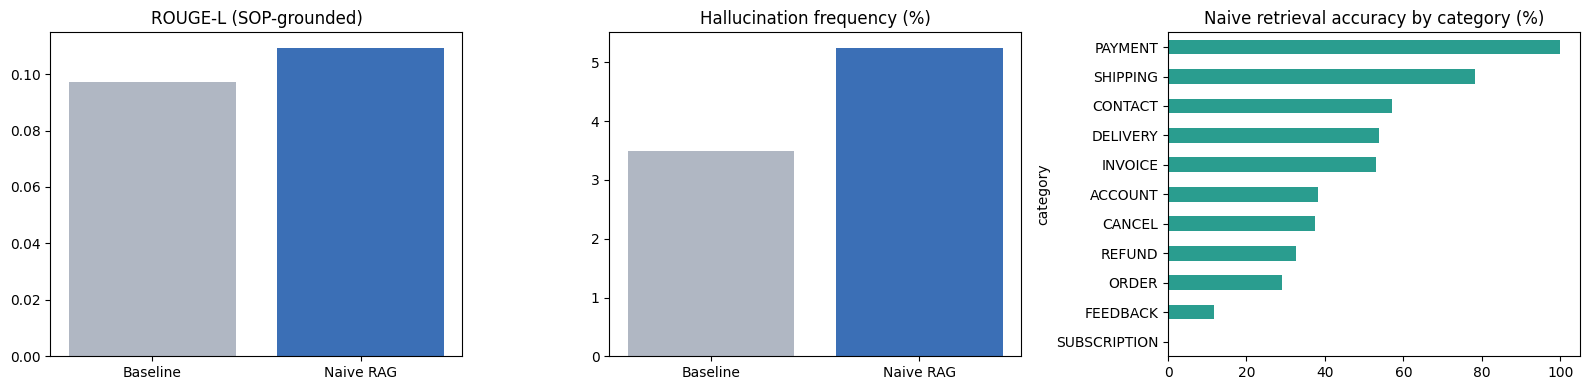


FINDINGS: retrieval changes ROUGE-L by +12.6% and hallucination frequency by +1.7 points;
however only 45% of raw queries fetch the right SOP, and answers built on a wrong SOP score lower - motivating the fine-tuned intent router (Stage 4).


In [15]:
# ---- Ensure reference column is populated ----------------------------------------------------------------
if "reference" not in results.columns:
    results["reference"] = [build_reference(q, s) for q, s in zip(results["query"], results["true_sop"])]

# ---- Ensure all metric columns are populated in the results DataFrame ----------------------------------
for tag, col in [("base", "baseline_output"), ("naive", "naive_output")]:
    if f"rouge1_{tag}" not in results.columns:
        sc = [score_output(o, ref) for o, ref in zip(results[col], results["reference"])]
        results[f"rouge1_{tag}"], results[f"rougeL_{tag}"], results[f"bleu_{tag}"] = zip(*sc)

# ---- Now build the summary DataFrame safely ------------------------------------------------------------
summary = pd.DataFrame([
    ("Format adherence - well-formed (%)", results.wellformed_base.mean()*100, results.wellformed_naive.mean()*100, True),
    ("Functional correctness: ROUGE-1",    results.rouge1_base.mean(), results.rouge1_naive.mean(), True),
    ("Functional correctness: ROUGE-L",    results.rougeL_base.mean(), results.rougeL_naive.mean(), True),
    ("Functional correctness: BLEU",       results.bleu_base.mean(),   results.bleu_naive.mean(), True),
    ("Consistency rate (%)",               cons_base, cons_naive, True),
    ("Hallucination frequency (%)",        h_base, h_naive, False),
], columns=["Metric", "Baseline", "Naive RAG (V1)", "higher_is_better"])
summary["Change (abs)"] = summary["Naive RAG (V1)"] - summary["Baseline"]
summary["Change (%)"] = [pct_change(n, b) for n, b in zip(summary["Naive RAG (V1)"], summary["Baseline"])]
summary["Improvement (%)"] = [c if hib else (-c if not pd.isna(c) else c) for c, hib in zip(summary["Change (%)"], summary["higher_is_better"])]
display(summary.drop(columns="higher_is_better").round(4))

# ---- WHERE does retrieval help and where does it not? ---------------------------------------------------
ret_acc = results.naive_retrieval_correct.mean() * 100
print(f"\nNaive retrieval accuracy (top-1 SOP == correct SOP): {ret_acc:.1f}%  ({int(results.naive_retrieval_correct.sum())}/{len(results)})")
by_hit = results.groupby("naive_retrieval_correct").agg(n=("query", "size"), rougeL=("rougeL_naive", "mean"), halluc_pct=("halluc_naive", lambda s: s.mean()*100)).round(3)
by_hit.index = by_hit.index.map({0: "wrong SOP retrieved", 1: "correct SOP retrieved"})
display(by_hit)
by_cat = results.groupby("category").agg(n=("query", "size"), retrieval_acc=("naive_retrieval_correct", lambda s: s.mean()*100),
                                          dRougeL=("rougeL_naive", "mean")).round(2).sort_values("retrieval_acc")
by_cat["dRougeL"] = by_cat["dRougeL"] - results.groupby("category")["rougeL_base"].mean()
display(by_cat.rename(columns={"dRougeL": "ROUGE-L gain vs baseline"}))
print("Weakest categories for naive retrieval:", ", ".join(by_cat.index[:3]))

# ---- plot ---------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].bar(["Baseline", "Naive RAG"], [results.rougeL_base.mean(), results.rougeL_naive.mean()], color=["#b0b7c3", "#3b6fb6"]); ax[0].set_title("ROUGE-L (SOP-grounded)")
ax[1].bar(["Baseline", "Naive RAG"], [h_base, h_naive], color=["#b0b7c3", "#3b6fb6"]); ax[1].set_title("Hallucination frequency (%)")
by_cat["retrieval_acc"].plot.barh(ax=ax[2], color="#2a9d8f"); ax[2].set_title("Naive retrieval accuracy by category (%)")
plt.tight_layout(); plt.show()

print(f"\nFINDINGS: retrieval changes ROUGE-L by {summary.loc[2,'Change (%)']:+.1f}% and hallucination frequency by {summary.loc[5,'Change (abs)']:+.1f} points;")
print(f"however only {ret_acc:.0f}% of raw queries fetch the right SOP, and answers built on a wrong SOP score lower - motivating the fine-tuned intent router (Stage 4).")

In [16]:
import shutil
import os

source_path = "/content/v1_raw_outputs.csv"
dest_dir = "/content/drive/MyDrive/RAG/Dataset/Output/"
dest_path = os.path.join(dest_dir, "v1_raw_outputs.csv")

if os.path.exists(source_path):
    os.makedirs(dest_dir, exist_ok=True)
    shutil.move(source_path, dest_path)
    print(f"Successfully moved {source_path} to {dest_path}")
else:
    print(f"Source file {source_path} not found. Please ensure it exists.")

Successfully moved /content/v1_raw_outputs.csv to /content/drive/MyDrive/RAG/Dataset/Output/v1_raw_outputs.csv


In [17]:
import json
import os
import pandas as pd

target_dir = "/content/drive/MyDrive/RAG/Dataset/Output/"
os.makedirs(target_dir, exist_ok=True)

# Define the metric columns to save
keep = ["row_id", "query", "intent", "category", "true_sop", "reference", "baseline_output",
        "naive_output", "naive_source", "naive_retrieval_correct", "wellformed_base",
        "wellformed_naive", "rouge1_base", "rougeL_base", "bleu_base", "rouge1_naive",
        "rougeL_naive", "bleu_naive", "halluc_base", "halluc_naive"]

# Save files directly to Drive
results[keep].to_csv(os.path.join(target_dir, "v1_metrics.csv"), index=False)
summary.drop(columns="higher_is_better").to_csv(os.path.join(target_dir, "v1_summary.csv"), index=False)

extra_data = {
    "consistency_baseline": float(cons_base),
    "consistency_naive": float(cons_naive),
    "n_eval": len(results),
    "naive_retrieval_accuracy": float(ret_acc)
}

with open(os.path.join(target_dir, "v1_extra.json"), "w") as f:
    json.dump(extra_data, f, indent=2)

print(f"All artifacts saved successfully in {target_dir}!")

All artifacts saved successfully in /content/drive/MyDrive/RAG/Dataset/Output/!


In [18]:
import shutil
import os

local_chroma_path = "./chroma_db"
drive_chroma_path = "/content/drive/MyDrive/RAG/Dataset/Output/chroma_db"

if os.path.exists(local_chroma_path):
    # Ensure destination parent directory exists
    os.makedirs(os.path.dirname(drive_chroma_path), exist_ok=True)

    # Move or copy the directory safely
    if os.path.exists(drive_chroma_path):
        print(f"Destination directory already exists at {drive_chroma_path}.")
    else:
        shutil.copytree(local_chroma_path, drive_chroma_path)
        print(f"Successfully copied Chroma DB from {local_chroma_path} to {drive_chroma_path}!")
        print("\nMake sure to update your config or notebook's CHROMA_DIR variable to load from Google Drive in subsequent notebooks!")
else:
    print(f"Local chroma_db folder '{local_chroma_path}' was not found in the current working directory.")

Successfully copied Chroma DB from ./chroma_db to /content/drive/MyDrive/RAG/Dataset/Output/chroma_db!

Make sure to update your config or notebook's CHROMA_DIR variable to load from Google Drive in subsequent notebooks!


In [19]:
import shutil
import os

source_dir = "/content/chroma_db"
dest_dir = "/content/drive/MyDrive/RAG/Dataset/Output/chroma_db"

if os.path.exists(source_dir):
    os.makedirs(os.path.dirname(dest_dir), exist_ok=True)
    if os.path.exists(dest_dir):
        shutil.rmtree(dest_dir)
    shutil.move(source_dir, dest_dir)
    print(f"Successfully moved {source_dir} to {dest_dir}")
else:
    print(f"Source folder {source_dir} not found. Please ensure it exists.")

Successfully moved /content/chroma_db to /content/drive/MyDrive/RAG/Dataset/Output/chroma_db


---
## Save Artifacts

In [ ]:
keep = ["row_id", "query", "intent", "category", "true_sop", "reference", "baseline_output", "naive_output", "naive_source", "naive_retrieval_correct",
        "wellformed_base", "wellformed_naive", "rouge1_base", "rougeL_base", "bleu_base", "rouge1_naive", "rougeL_naive", "bleu_naive", "halluc_base", "halluc_naive"]
results[keep].to_csv("v1_metrics.csv", index=False)          # per-row Baseline vs V1 scores
summary.drop(columns="higher_is_better").to_csv("v1_summary.csv", index=False)
json.dump({"consistency_baseline": cons_base, "consistency_naive": cons_naive, "n_eval": len(results), "naive_retrieval_accuracy": ret_acc},
          open("v1_extra.json", "w"), indent=2)
print("Saved v1_metrics.csv", pd.read_csv("v1_metrics.csv").shape, "| v1_summary.csv | v1_extra.json")

Saved v1_metrics.csv (400, 20) | v1_summary.csv | v1_extra.json


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 6.**

- [ ] ChromaDB reloaded from `./chroma_db/`
- [ ] **3.3.1** Automated testing run across full test set
- [ ] **3.3.2** Format adherence measured
- [ ] **3.3.3** ROUGE/BLEU computed with SOP-grounded references
- [ ] **3.3.4** Output consistency (determinism) verified
- [ ] **3.3.5** Hallucination frequency quantified
- [ ] **3.4.1** Retrieval impact quantified with improvement %
- [ ] **`v1_metrics.csv` saved** ← _Evidence for comparative analysis_

**If any item is unchecked, fix it before moving on.**